In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score 
import matplotlib.pyplot as plt
import seaborn as sns

Load Data:

In [3]:
# 1. Dataset Generation and Exploration
df = pd.read_csv("loan_data.csv")
df.head()
df
df.info()
df.isnull().sum()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

(45000, 14)

Expolatory Data Analysis: EDA

Text(0.5, 1.0, 'Is Loan Approved or Not?')

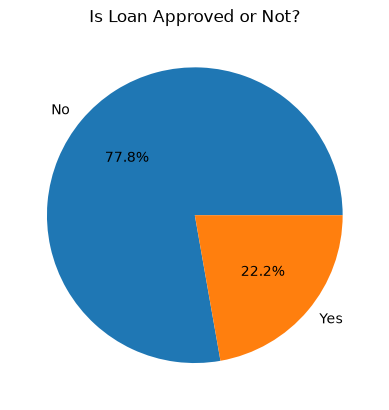

In [4]:
classes_count = df["loan_status"].value_counts()
plt.pie(classes_count, labels=["No", "Yes"], autopct="%1.1f%%")
plt.title("Is Loan Approved or Not?")

<Axes: xlabel='person_gender', ylabel='count'>

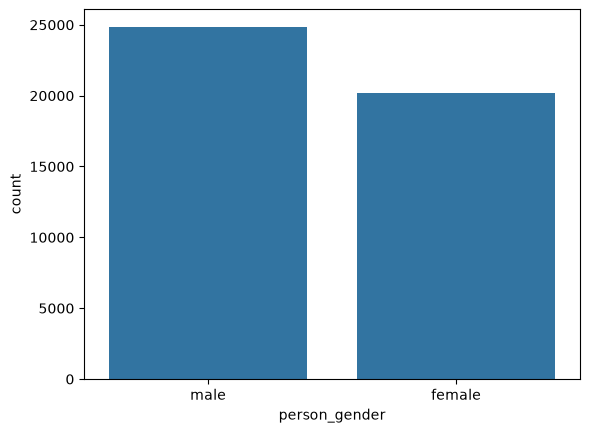

In [5]:
# Analyze Categories

gender_count = df["person_gender"].value_counts()
sns.barplot(gender_count)


[Text(0, 0, '24841'), Text(0, 0, '20159')]

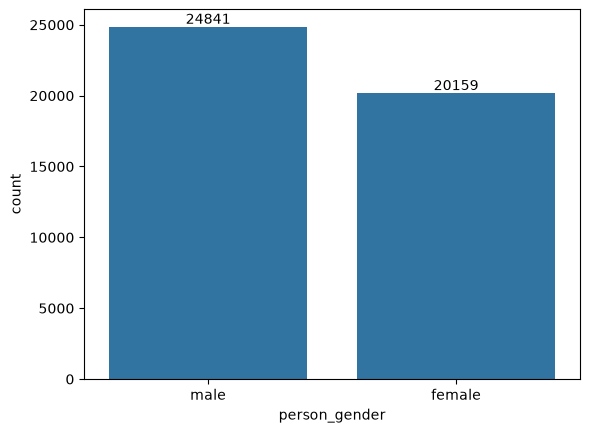

In [6]:
ax = sns.barplot(gender_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '13399'),
 Text(0, 0, '12028'),
 Text(0, 0, '11972'),
 Text(0, 0, '6980'),
 Text(0, 0, '621')]

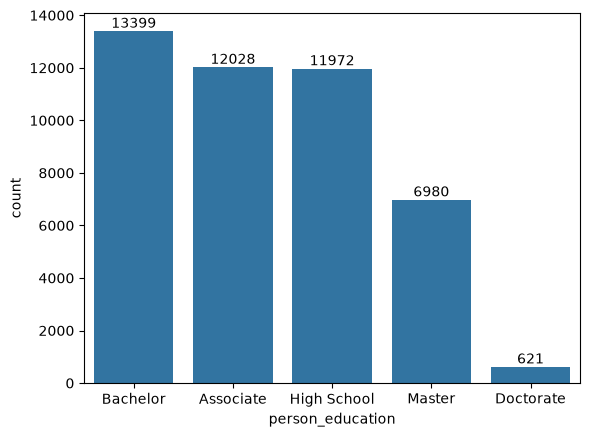

In [7]:
education_count = df["person_education"].value_counts()
ax = sns.barplot(education_count)
ax.bar_label(ax.containers[0])

# print(education_count)

In [8]:
df["person_income"].describe()

count    4.500000e+04
mean     8.031905e+04
std      8.042250e+04
min      8.000000e+03
25%      4.720400e+04
50%      6.704800e+04
75%      9.578925e+04
max      7.200766e+06
Name: person_income, dtype: float64

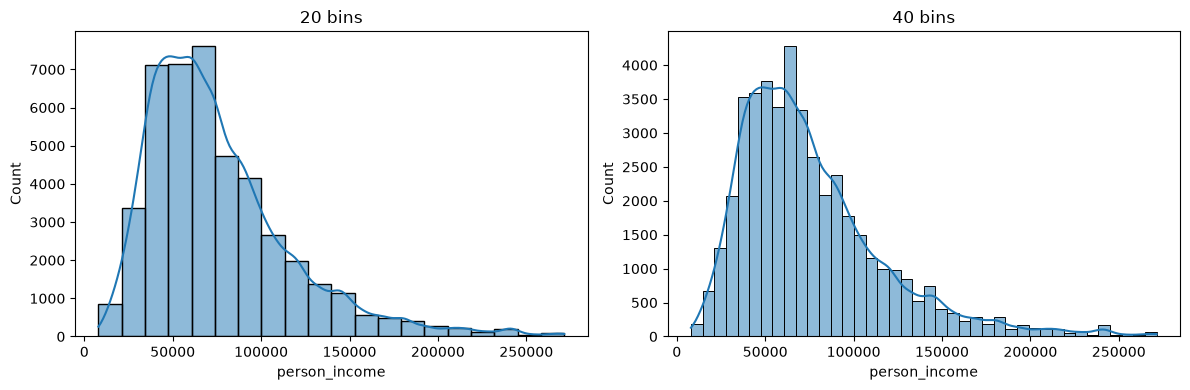

In [9]:
# sns.histplot(data = df, x = "person_income", bins = 20)
df["person_income"].describe()
cap = df["person_income"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df[df["person_income"] <= cap], x="person_income", bins=20, kde=True, ax=axes[0])
axes[0].set_title("20 bins")
sns.histplot(data=df[df["person_income"] <= cap], x="person_income", bins=40, kde=True, ax=axes[1])
axes[1].set_title("40 bins")
plt.tight_layout()
plt.show()



In [10]:
df["person_income"].describe()

count    4.500000e+04
mean     8.031905e+04
std      8.042250e+04
min      8.000000e+03
25%      4.720400e+04
50%      6.704800e+04
75%      9.578925e+04
max      7.200766e+06
Name: person_income, dtype: float64

In [11]:
df['loan_amnt'].describe()
# df["loan_amnt"].quantile(0.75)

count    45000.000000
mean      9583.157556
std       6314.886691
min        500.000000
25%       5000.000000
50%       8000.000000
75%      12237.250000
max      35000.000000
Name: loan_amnt, dtype: float64

<Axes: xlabel='loan_amnt', ylabel='Count'>

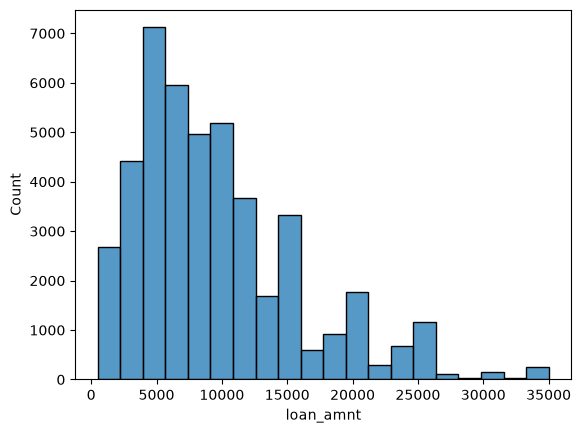

In [12]:
sns.histplot(data = df, x = "loan_amnt", bins=20)

<Axes: xlabel='loan_status', ylabel='person_income'>

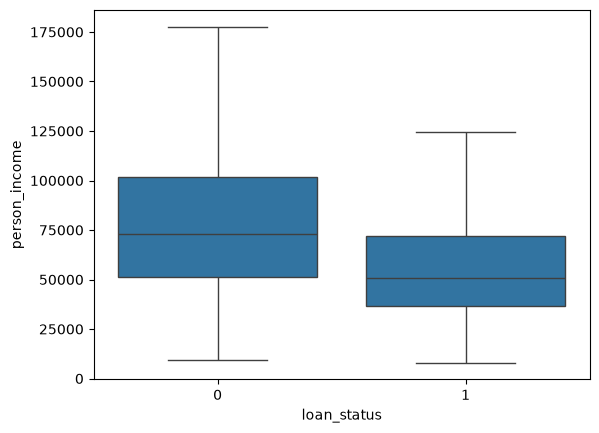

In [13]:
# Outliers - Box Plots:
# print(df.columns.tolist())
sns.boxplot(data = df, x = "loan_status", y="person_income", showfliers=False)

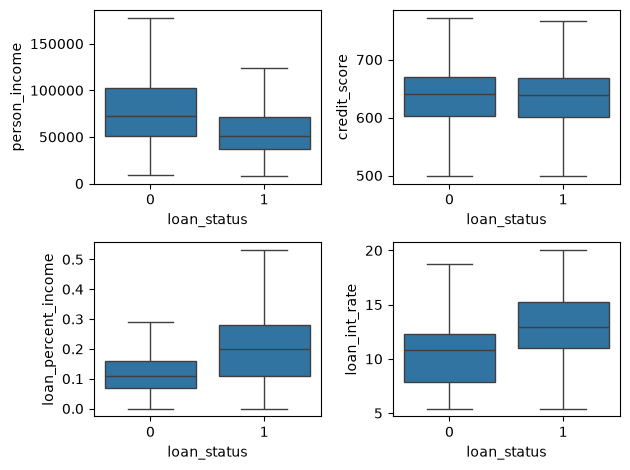

In [14]:
fig, axis = plt. subplots(2, 2)

sns.boxplot(ax = axis[0, 0], data=df, x = "loan_status", y = "person_income", showfliers=False)
sns.boxplot(ax = axis[0, 1], data=df, x = "loan_status", y = "credit_score", showfliers=False)
sns.boxplot(ax = axis[1, 0], data=df, x = "loan_status", y = "loan_percent_income", showfliers=False)
sns.boxplot(ax = axis[1, 1], data=df, x = "loan_status", y = "loan_int_rate", showfliers=False)

plt.tight_layout()




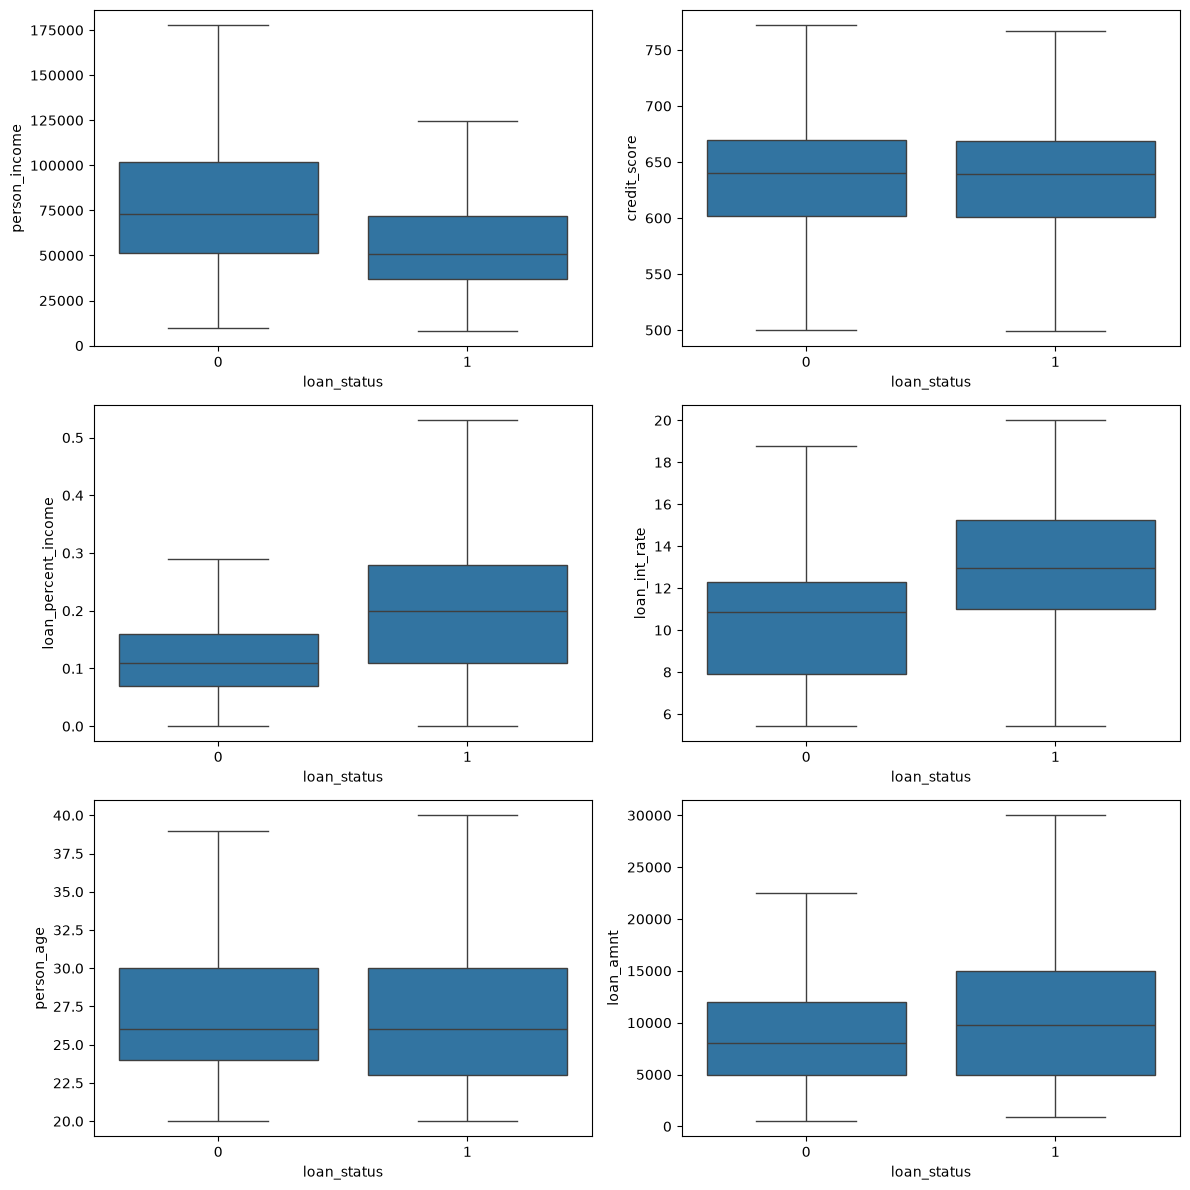

In [15]:
fig, axis = plt.subplots(3, 2, figsize=(12, 12))

sns.boxplot(ax = axis[0, 0], data=df, x = "loan_status", y = "person_income", showfliers=False)
sns.boxplot(ax = axis[0, 1], data=df, x = "loan_status", y = "credit_score", showfliers=False)
sns.boxplot(ax = axis[1, 0], data=df, x = "loan_status", y = "loan_percent_income", showfliers=False)
sns.boxplot(ax = axis[1, 1], data=df, x = "loan_status", y = "loan_int_rate", showfliers=False)
sns.boxplot(ax = axis[2, 0], data = df, x = "loan_status", y = "person_age", showfliers=False)
sns.boxplot(ax = axis[2, 1], data=df, x="loan_status", y="loan_amnt", showfliers=False)

plt.tight_layout()
plt.show()


<Axes: xlabel='credit_score', ylabel='Count'>

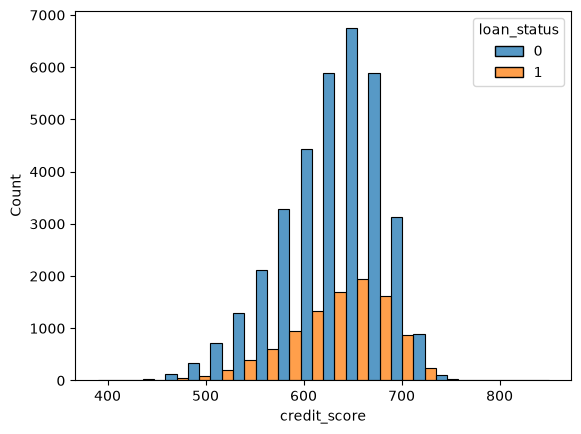

In [16]:
# Credit Score with Loan Approved 

sns.histplot(data = df, x = "credit_score", hue = "loan_status", bins = 20, multiple = "dodge")

<Axes: xlabel='person_income', ylabel='Count'>

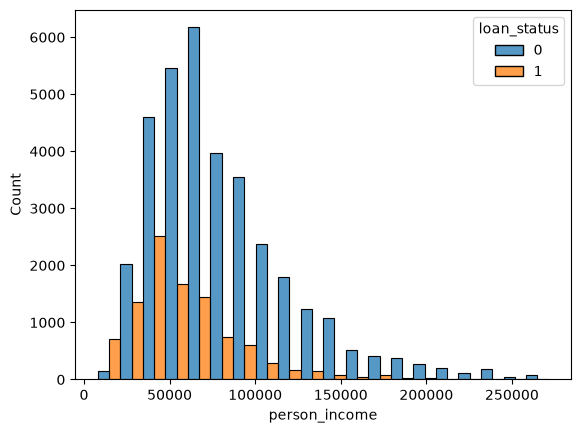

In [17]:
# sns.histplot(data = df, x = "person_income", hue = 'loan_status', bins = 20, multiple = "dodge")

# plot the incomes up to the 99th percentile by applying the filtering
cap = df["person_income"].quantile(0.99)
sns.histplot(data=df[df["person_income"] <= cap], x = "person_income", hue = "loan_status", bins = 20, multiple = "dodge")

Feature Encoding:

In [18]:
df.head()
len(df.columns)

14

Features and Target

In [19]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

print(X.shape)
X.head()

(45000, 22)


,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,person_gender_male,person_education_Bachelor,person_education_Doctorate,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_Yes
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561,0,0,0,0,1,0,0,1,0,0,0,1,0,0
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504,0,0,0,1,0,0,1,0,1,0,0,0,0,1
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635,0,0,0,1,0,0,0,0,0,0,1,0,0,0
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675,0,1,0,0,0,0,0,1,0,0,1,0,0,0
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586,1,0,0,0,1,0,0,1,0,0,1,0,0,0


In [20]:
print(X.columns.tolist())
print(X.info())

['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'person_gender_male', 'person_education_Bachelor', 'person_education_Doctorate', 'person_education_High School', 'person_education_Master', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'previous_loan_defaults_on_file_Yes']
<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 22 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   person_age                          45000 non-null  float64
 1   person_income                       45000 non-null  float64
 2   person_emp_exp                      45000 non-null  int64  
 3   loan_amnt                    

In [21]:
data = X.copy()
data["loan_status"] = y

data.corr()["loan_status"].sort_values(ascending=False)


loan_status                           1.000000
loan_percent_income                   0.384880
loan_int_rate                         0.332005
person_home_ownership_RENT            0.255239
loan_amnt                             0.107714
loan_intent_MEDICAL                   0.065195
loan_intent_HOMEIMPROVEMENT           0.033838
person_home_ownership_OTHER           0.013645
person_education_Bachelor             0.004728
person_education_Doctorate            0.001833
person_education_High School          0.001277
person_gender_male                   -0.000561
person_education_Master              -0.004741
credit_score                         -0.007647
cb_person_cred_hist_length           -0.014851
person_emp_exp                       -0.020481
person_age                           -0.021476
loan_intent_PERSONAL                 -0.022488
loan_intent_EDUCATION                -0.064006
loan_intent_VENTURE                  -0.085992
person_home_ownership_OWN            -0.093666
person_income

<Axes: >

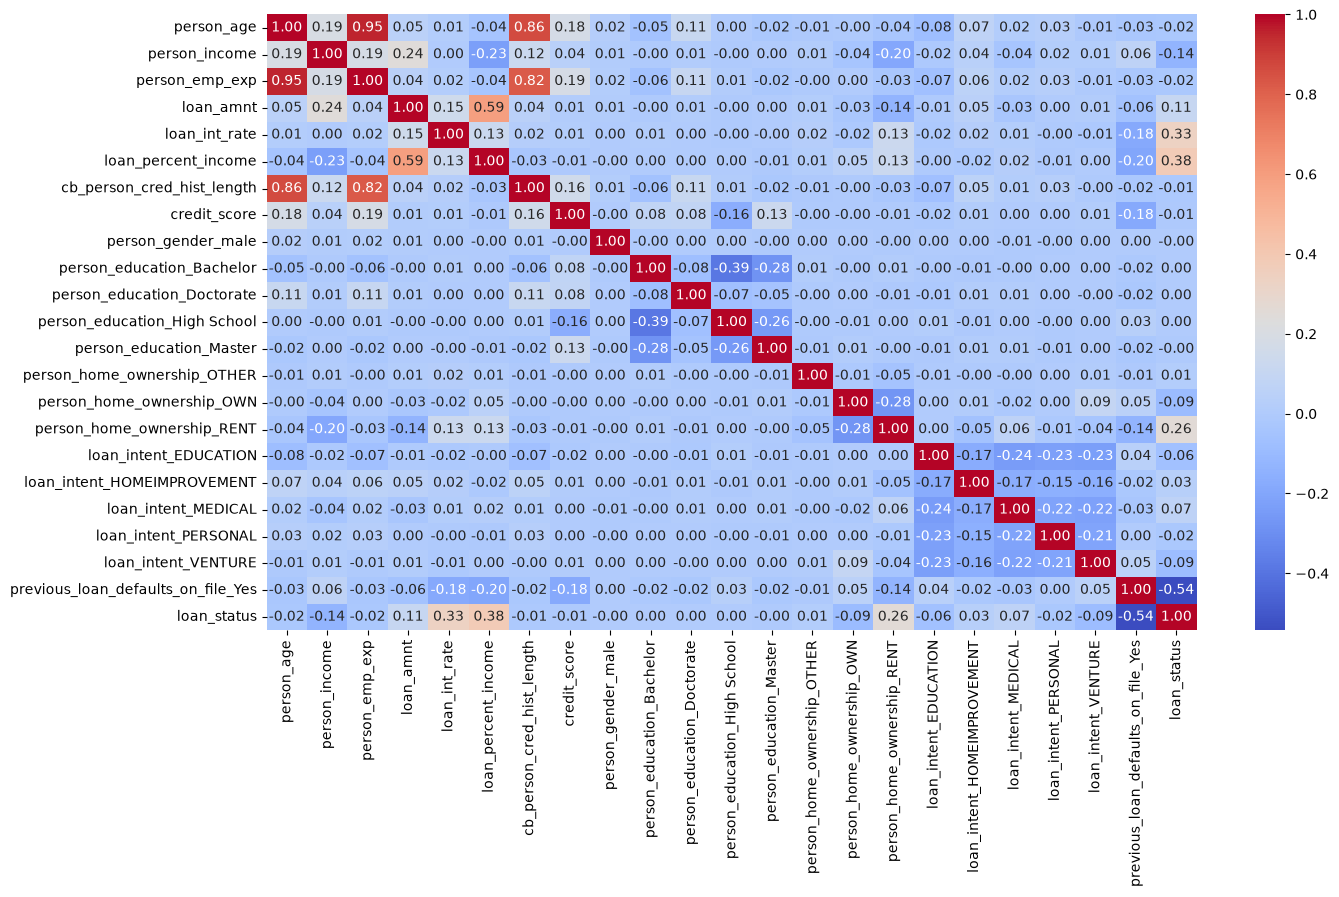

In [22]:
corr_matrix = data.corr()

plt.figure(figsize=(15, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")

Train, Test and Split:

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
X_test.head()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,person_gender_male,person_education_Bachelor,person_education_Doctorate,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_Yes
37979,32.0,96865.0,10,7500.0,6.04,0.08,10.0,601,1,0,0,0,0,0,0,0,1,0,0,0,0,0
9911,24.0,56838.0,6,9000.0,11.49,0.16,4.0,647,1,0,0,0,0,0,0,1,1,0,0,0,0,1
43386,22.0,37298.0,0,5000.0,14.88,0.13,4.0,711,0,0,0,0,1,0,0,1,0,0,1,0,0,0
13822,23.0,39944.0,1,5000.0,13.99,0.13,3.0,597,0,1,0,0,0,0,1,0,0,0,0,0,1,1
44810,42.0,67974.0,20,10000.0,15.41,0.15,11.0,586,1,0,0,1,0,0,0,0,0,1,0,0,0,0


Model Training & Evaluation:

Decision Tree Algorithm Model:

In [25]:
# Decision Tree Classifier (With entropy and depth regularization)
dt_clf = DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_split=5, random_state=42)
dt_clf.fit(X_train, y_train)
dt_preds = dt_clf.predict(X_test)
dt_acc = accuracy_score(y_test, dt_preds)


In [26]:
# for depth in [10, 12, 15, 20]:
#     tree = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=42)
#     score = cross_val_score(tree, X_train, y_train, cv=5, scoring="f1").mean()
#     print(depth, round(score, 3))

In [27]:
# Evaluation Matrics:
print("1. Decision Tree Accuracy:", f"{dt_acc * 100:.2f}%")
print("Precison: ", precision_score(y_test, dt_preds))
print("Recall Score: ", recall_score(y_test, dt_preds))
print("F1 Score: ", f1_score(y_test, dt_preds))
print("Confusion Matrix:\n ", confusion_matrix(y_test, dt_preds))
# print(export_text(dt_clf, feature_names=list))

1. Decision Tree Accuracy: 91.94%
Precison:  0.8759508484493856
Recall Score:  0.744776119402985
F1 Score:  0.8050551223447163
Confusion Matrix:
  [[6778  212]
 [ 513 1497]]


In [28]:
# for n in [50, 100, 200, 300]:
#     rf = RandomForestClassifier(n_estimators=n, max_features='sqrt', random_state=42)
#     score = cross_val_score(rf, X_train, y_train, cv=5, scoring='f1').mean()
#     print(n, round(score, 3))

In [29]:
# RandomForestClassifier
rf_clf = RandomForestClassifier(n_estimators=50, max_features='sqrt', random_state=42)
rf_clf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf_clf.predict(X_test))
print("2. RandomForestClassifier Accuracy:", f"{rf_acc * 100:.2f}%")
print("Precison: ", precision_score(y_test, rf_clf.predict(X_test)))
print("Recall Score: ", recall_score(y_test, rf_clf.predict(X_test)))
print("F1 Score: ", f1_score(y_test, rf_clf.predict(X_test)))
print("Confusion Matrix:\n ", confusion_matrix(y_test, rf_clf.predict(X_test)))

2. RandomForestClassifier Accuracy: 92.88%
Precison:  0.898196625945317
Recall Score:  0.7681592039800995
F1 Score:  0.8281040493429874
Confusion Matrix:
  [[6815  175]
 [ 466 1544]]


In [30]:
# for depth in [3, 4, 5]:
#     for lr in [0.5, 1.0]:
#         ada_clf = AdaBoostClassifier(
#             estimator=DecisionTreeClassifier(max_depth=depth), 
#             n_estimators=50, 
#             learning_rate=lr, 
#             random_state=42
#         )
#         score = cross_val_score(ada_clf, X_train, y_train, cv=5, scoring='f1').mean()
#         print(depth, lr, round(score, 3))

In [31]:
# AdaBoostClassfiers
ada_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=4),
    n_estimators=50,
    learning_rate=1.0, 
    random_state=42
)
ada_clf.fit(X_train, y_train)
ada_acc = accuracy_score(y_test, ada_clf.predict(X_test))
print("3. AdaBoostClassifier Accuracy:", f"{ada_acc * 100:.2f}%")
print("Precison: ", precision_score(y_test, ada_clf.predict(X_test)))
print("Recall Score: ", recall_score(y_test, ada_clf.predict(X_test)))
print("F1 Score: ", f1_score(y_test, ada_clf.predict(X_test)))
print("Confusion Matrix:\n ", confusion_matrix(y_test, ada_clf.predict(X_test)))

3. AdaBoostClassifier Accuracy: 92.26%
Precison:  0.8645197112715158
Recall Score:  0.7746268656716417
F1 Score:  0.8171083705064287
Confusion Matrix:
  [[6746  244]
 [ 453 1557]]


In [36]:

gb_clf = GradientBoostingClassifier(n_estimators=100, max_depth=6, learning_rate=0.2, random_state=42)
gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_test)

gb_acc = accuracy_score(y_test, gb_preds)
print("4. GradientBoostingClassifier Accuracy:", f"{gb_acc * 100:.2f}%")
print("Precison: ", precision_score(y_test, gb_preds))
print("Recall Score: ", recall_score(y_test, gb_preds))
print("F1 Score: ", f1_score(y_test, gb_preds))
print("Confusion Matrix:\n ", confusion_matrix(y_test, gb_preds))

4. GradientBoostingClassifier Accuracy: 93.49%
Precison:  0.8920704845814978
Recall Score:  0.8059701492537313
F1 Score:  0.8468374281233665
Confusion Matrix:
  [[6794  196]
 [ 390 1620]]
